<a href="https://colab.research.google.com/github/nisaerdemli/imageprocessing/blob/main/hafta10ek%C3%B6dev_jynb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Toplam piksel sayisi            : 110592
Eslestirilen kenar piksel sayisi: 11905 (%10.76)
Seyrek (Sparse) Stereo Suresi   : 8.7011 sn
Yogun (Dense) Stereo Suresi     : 0.0697 sn
Kenar noktalarinda ortalama fark: 0.00 piksel


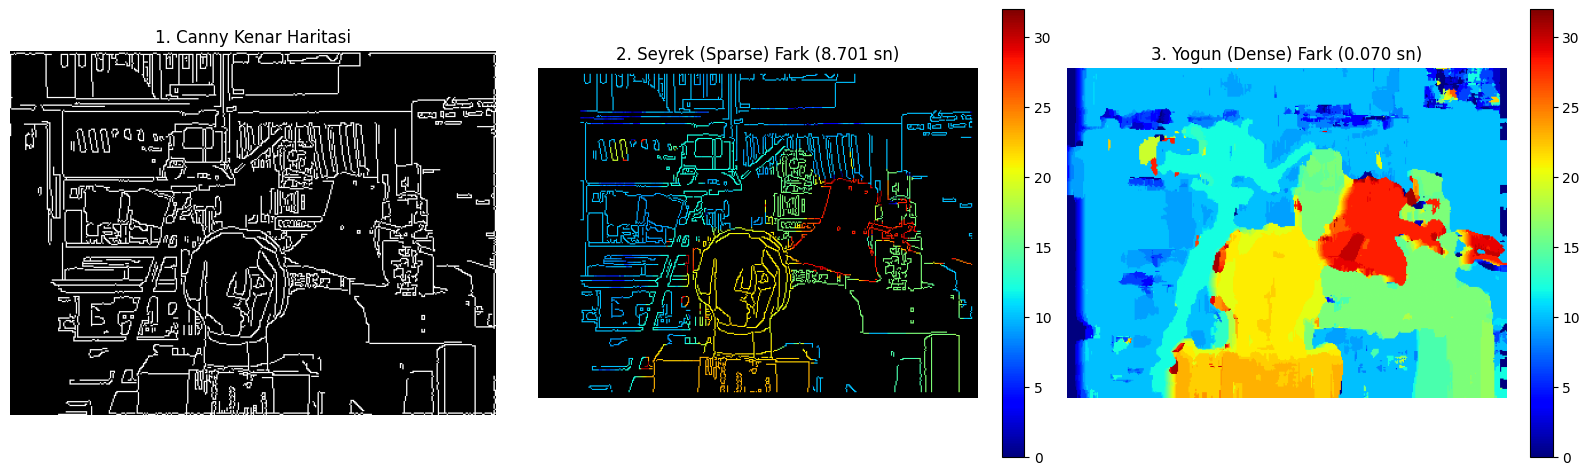

In [1]:
from pathlib import Path
import time
import urllib.request
import zipfile
import cv2
import matplotlib.pyplot as plt
import numpy as np

# 1. Rectified stereo goruntu ciftini (Tsukuba 1. ve 3. kareler) hazirla
url = "https://vision.middlebury.edu/stereo/data/scenes2001/data/tsukuba/tsukuba.zip"
zip_path = Path("tsukuba.zip")
extract_dir = Path("tsukuba_data")
valid_exts = {".ppm", ".pgm", ".png", ".jpg", ".jpeg"}

img_files = (
    sorted([p for p in extract_dir.rglob("*") if p.suffix.lower() in valid_exts])
    if extract_dir.exists()
    else []
)

if len(img_files) < 3:
  if zip_path.exists() and not zipfile.is_zipfile(zip_path):
    zip_path.unlink()
  if not zip_path.exists():
    req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
    with urllib.request.urlopen(req, timeout=30) as resp, open(
        zip_path, "wb"
    ) as f:
      f.write(resp.read())
  with zipfile.ZipFile(zip_path, "r") as zf:
    zf.extractall(extract_dir)
  img_files = sorted(
      [p for p in extract_dir.rglob("*") if p.suffix.lower() in valid_exts]
  )

left_img = cv2.imread(str(img_files[0]))
right_img = cv2.imread(str(img_files[2]))
left_gray = cv2.cvtColor(left_img, cv2.COLOR_BGR2GRAY)
right_gray = cv2.cvtColor(right_img, cv2.COLOR_BGR2GRAY)

# --- YONTEM A: SEYREK (SPARSE) STEREO (Sadece Kenar Bolgeleri) ---
t0 = time.perf_counter()

# 1) Kenarlari bul (Canny)
edges_left = cv2.Canny(left_gray, threshold1=80, threshold2=180)
edge_ys, edge_xs = np.where(edges_left > 0)

# 2) Sadece kenar pikselleri cevresindeki yamalar icin SAD ile eslestirme yap
left_f = left_gray.astype(np.float32)
right_f = right_gray.astype(np.float32)

win = 11
half = win // 2
max_disp = 32
h, w = left_gray.shape

sparse_disp = np.full((h, w), np.nan, dtype=np.float32)

for y, x in zip(edge_ys, edge_xs):
  # Pencere sinirlari ve sola kayma siniri kontrolu
  if y < half or y >= h - half or x < half + max_disp or x >= w - half:
    continue

  patch_l = left_f[y - half : y + half + 1, x - half : x + half + 1]
  best_cost = np.inf
  best_d = 0

  # Rectified goruntude arama sadece ayni satir (y) uzerinde sola dogru yapilir
  for d in range(max_disp):
    rx = x - d
    patch_r = right_f[y - half : y + half + 1, rx - half : rx + half + 1]
    cost = np.sum(np.abs(patch_l - patch_r))
    if cost < best_cost:
      best_cost = cost
      best_d = d

  sparse_disp[y, x] = best_d

sparse_time = time.perf_counter() - t0

# --- YONTEM B: YOGUN (DENSE) STEREO (Tum Pikseller - Blok Eslestirme) ---
t1 = time.perf_counter()

cost_vol = np.full((h, w, max_disp), np.inf, dtype=np.float32)
for d in range(max_disp):
  if d == 0:
    shifted_r = right_f
  else:
    shifted_r = np.zeros_like(right_f)
    shifted_r[:, d:] = right_f[:, :-d]
  cost_vol[:, :, d] = cv2.boxFilter(
      np.abs(left_f - shifted_r), -1, (win, win), normalize=False
  )

dense_disp = np.argmin(cost_vol, axis=2).astype(np.float32)
dense_time = time.perf_counter() - t1

# --- SAYISAL KIYASLAMA ---
valid_sparse_mask = ~np.isnan(sparse_disp)
matched_edge_count = int(np.sum(valid_sparse_mask))
total_pixels = h * w
coverage_pct = (matched_edge_count / total_pixels) * 100.0

# Kenar noktalarinda seyrek ve yogun tahminlerin ortalama mutlak farki
mae_on_edges = np.mean(
    np.abs(sparse_disp[valid_sparse_mask] - dense_disp[valid_sparse_mask])
)

print(f"Toplam piksel sayisi            : {total_pixels}")
print(f"Eslestirilen kenar piksel sayisi: {matched_edge_count} (%{coverage_pct:.2f})")
print(f"Seyrek (Sparse) Stereo Suresi   : {sparse_time:.4f} sn")
print(f"Yogun (Dense) Stereo Suresi     : {dense_time:.4f} sn")
print(f"Kenar noktalarinda ortalama fark: {mae_on_edges:.2f} piksel")

# --- GORSELLESTIRME ---
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))

axes[0].imshow(edges_left, cmap="gray")
axes[0].set_title("1. Canny Kenar Haritasi")
axes[0].axis("off")

# Seyrek fark haritasini siyah arka plan uzerinde net goster
sparse_vis = np.ma.masked_invalid(sparse_disp)
cmap_jet = plt.cm.jet.copy()
cmap_jet.set_bad(color="black")

im1 = axes[1].imshow(sparse_vis, cmap=cmap_jet, vmin=0, vmax=max_disp)
axes[1].set_title(f"2. Seyrek (Sparse) Fark ({sparse_time:.3f} sn)")
axes[1].axis("off")
plt.colorbar(im1, ax=axes[1], fraction=0.046)

im2 = axes[2].imshow(dense_disp, cmap="jet", vmin=0, vmax=max_disp)
axes[2].set_title(f"3. Yogun (Dense) Fark ({dense_time:.3f} sn)")
axes[2].axis("off")
plt.colorbar(im2, ax=axes[2], fraction=0.046)

plt.tight_layout()
plt.show()